# بخش 3-1

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
import kagglehub
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

# path = kagglehub.dataset_download("camnugent/california-housing-prices")
# print("Path to dataset files:", path)

csv_path = "housing.csv"
df = pd.read_csv(csv_path)
X = df
# Split into features (X) and target (y)
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']
# X = pd.DataFrame(data.data, columns=data.feature_names)
# y = pd.Series(data.target, name='MedHouseVal')

print("شکل داده‌ها:", X.shape)
print("ویژگی‌ها:", X.columns.tolist())
print("\nاطلاعات اولیه:")
print(X.info())
print("target:")
print(y.info())
print(y.describe())

c:\Users\Ali.M\AppData\Local\Programs\Python\Python38\lib\site-packages\tqdm\auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


شکل داده‌ها: (20640, 9)
ویژگی‌ها: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity']

اطلاعات اولیه:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   ocean_proximity     20640 non-null  object 
dtypes: float64(8), object(1)
memory usage: 1.4+ MB
None
target:
<class 'pandas.core.series.Series'>
RangeIndex: 20640 entries, 0 to 20639
Series name: median

In [2]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder


print(X.isnull().sum())

numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = ['ocean_proximity']

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot',  OneHotEncoder(handle_unknown='ignore'))
])

preprocess = ColumnTransformer([
    ('num', num_pipe, numeric_features),
    ('cat', cat_pipe, categorical_features)
])

X_prep = preprocess.fit_transform(X)
X_prep = pd.DataFrame(X_prep)
print(X_prep.describe())

print("after preprocess:")
print(X_prep.isnull().sum())
print("new info:")
print(X_prep.info())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
ocean_proximity         0
dtype: int64
                 0             1             2             3             4   \
count  20640.000000  20640.000000  20640.000000  20640.000000  20640.000000   
mean    -119.569704     35.631861     28.639486   2635.763081    536.838857   
std        2.003532      2.135952     12.585558   2181.615252    419.391878   
min     -124.350000     32.540000      1.000000      2.000000      1.000000   
25%     -121.800000     33.930000     18.000000   1447.750000    297.000000   
50%     -118.490000     34.260000     29.000000   2127.000000    435.000000   
75%     -118.010000     37.710000     37.000000   3148.000000    643.250000   
max     -114.310000     41.950000     52.000000  39320.000000   6445.000000   

                 5             6         

In [3]:

print(f"befor outlier removal: {X_prep.shape} samples")
print((y.__class__))
Q1 = y.quantile(0.25)
Q3 = y.quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (y >= lower_bound) & (y <= upper_bound)
X_outlier = X_prep[outlier_mask]
y_outlier = y[outlier_mask]

print(f"after outlier removal: {X_outlier.shape[0]} samples")

befor outlier removal: (20640, 13) samples
<class 'pandas.core.series.Series'>
after outlier removal: 19569 samples


In [4]:
X_train, X_temp , y_train, y_temp = train_test_split(
    X_outlier, y_outlier, test_size=0.2, random_state=42
)

X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print(f"train {len(X_train)}")
print(f"validation: {len(X_val)}")
print(f"test: {len(X_test)}")

print(f"train {len(y_train)}")
print(f"validation: {len(y_val)}")
print(f"test: {len(y_test)}")

train 15655
validation: 1957
test: 1957
train 15655
validation: 1957
test: 1957


In [5]:
X_train_t = torch.FloatTensor(X_train.to_numpy())
X_val_t   = torch.FloatTensor(X_val.to_numpy())
X_test_t  = torch.FloatTensor(X_test.to_numpy())

print(y_val.shape)
y_train_t = torch.FloatTensor(y_train.to_numpy()).view(-1, 1)
y_val_t   = torch.FloatTensor(y_val.to_numpy()).view(-1, 1)
y_test_t  = torch.FloatTensor(y_test.to_numpy()).view(-1, 1)
print(y_val_t.shape)

(1957,)
torch.Size([1957, 1])


# بخش 3-2

In [107]:



class HousePriceNet(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_size, 8),
            nn.ReLU(),
            nn.Linear(8, 1)
        )

    def forward(self, x):
        return self.layers(x)

input_size = X_train.shape[1]
model = HousePriceNet(input_size)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {total_params}")

batch_size     = 64
learning_rate  = 0.1
optimizer      = optim.Adam(model.parameters(), lr=learning_rate)
criterion      = nn.MSELoss()               



Total trainable parameters: 121


# بخش 3-3

In [6]:
def my_mse(y_true, y_pred):
    return np.mean((y_true - y_pred) ** 2)

def my_rmse(y_true, y_pred):
    return np.sqrt(my_mse(y_true, y_pred))

def my_mae(y_true, y_pred):
    return np.mean(np.abs(y_true - y_pred))

def my_r2(y_true, y_pred):
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    return 1 - (ss_res / ss_tot)

In [95]:
batch_size     = 64
learning_rate  = 0.1
optimizer      = optim.Adam(model.parameters(), lr=learning_rate)
criterion      = nn.MSELoss()

train_ds = torch.utils.data.TensorDataset(X_train_t, y_train_t)
train_dl = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True)

val_ds = torch.utils.data.TensorDataset(X_val_t, y_val_t)
val_dl = torch.utils.data.DataLoader(val_ds, batch_size=batch_size)

epochs = 60
best_val_loss = float('inf')
best_state = None
loss_list_train = []
loss_list_val = []

for epoch in range(1, epochs + 1):
    
    model.train()
    train_loss = 0.0
    for xb, yb in train_dl:
        pred = model(xb)
        loss = criterion(pred, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * xb.size(0)
    train_loss /= len(train_dl.dataset)
    loss_list_train.append(train_loss)

    
    model.eval()
    with torch.no_grad():
        val_preds = model(X_val_t).numpy().flatten()
        val_true = y_val_t.numpy().flatten()
        val_loss = my_mse(val_true, val_preds)
        loss_list_val.append(val_loss)

    if val_loss < best_val_loss - 1e-4:
        best_val_loss = val_loss
        best_state = model.state_dict()
        wait = 0

    print(f"epoch  {epoch:03d} | train MSE: {train_loss:,.0f} | validation MSE: {val_loss:,.0f}")

model.load_state_dict(best_state)

model.eval()


epoch  001 | train MSE: 3,541,411,324 | validation MSE: 3,364,460,288
epoch  002 | train MSE: 3,507,749,688 | validation MSE: 3,403,275,776
epoch  003 | train MSE: 3,526,411,253 | validation MSE: 3,146,864,896
epoch  004 | train MSE: 3,502,892,467 | validation MSE: 3,104,301,056
epoch  005 | train MSE: 3,550,470,773 | validation MSE: 3,393,270,016
epoch  006 | train MSE: 3,510,452,556 | validation MSE: 3,241,207,296
epoch  007 | train MSE: 3,556,612,950 | validation MSE: 3,199,908,352
epoch  008 | train MSE: 3,518,633,338 | validation MSE: 3,122,386,176
epoch  009 | train MSE: 3,472,375,740 | validation MSE: 3,087,764,224
epoch  010 | train MSE: 3,496,433,374 | validation MSE: 3,345,808,640
epoch  011 | train MSE: 3,529,611,685 | validation MSE: 3,472,887,040
epoch  012 | train MSE: 3,539,791,802 | validation MSE: 3,105,078,528
epoch  013 | train MSE: 3,594,158,580 | validation MSE: 3,277,510,912
epoch  014 | train MSE: 3,447,688,117 | validation MSE: 3,096,451,840
epoch  015 | train M

In [99]:
with torch.no_grad():
    test_pred = model(X_test_t).numpy().flatten()
    test_true = y_test_t.numpy().flatten()

    final_train_pred = model(X_train_t).numpy().flatten()
    final_train_true = y_train_t.numpy().flatten()

    final_val_pred = model(X_val_t).numpy().flatten()
    final_val_true = y_val_t.numpy().flatten()

mse  = my_mse(final_train_true, final_train_pred)
rmse = my_rmse(final_train_true, final_train_pred)
mae  = my_mae(final_train_true, final_train_pred)
r2   = my_r2(final_train_true, final_train_pred)

mse_val  = my_mse(final_val_true, final_val_pred)
rmse_val = my_rmse(final_val_true, final_val_pred)
mae_val  = my_mae(final_val_true, final_val_pred)
r2_val   = my_r2(final_val_true, final_val_pred)


mse_trian  = my_mse(test_true, test_pred)
rmse_trian = my_rmse(test_true, test_pred)
mae_trian  = my_mae(test_true, test_pred)
r2_trian   = my_r2(test_true, test_pred)


print("\n" + "="*50)
print("total report of train")
print("="*50)
print(f"RMSE  : {rmse_trian:,.0f} $")
print(f"MSE   : {mse_trian:,.0f}")
print(f"MAE   : {mae_trian:,.0f} $")
print(f"R²    : {r2_trian:.4f}")

print("\n" + "="*50)
print("total report of Val")
print("="*50)
print(f"RMSE  : {rmse_val:,.0f} $")
print(f"MSE   : {mse_val:,.0f}")
print(f"MAE   : {mae_val:,.0f} $")
print(f"R²    : {r2_val:.4f}")

print("\n" + "="*50)
print("total report of test")
print("="*50)
print(f"RMSE  : {rmse:,.0f} $")
print(f"MSE   : {mse:,.0f}")
print(f"MAE   : {mae:,.0f} $")
print(f"R²    : {r2:.4f}")


total report of train
RMSE  : 59,283 $
MSE   : 3,514,505,728
MAE   : 42,323 $
R²    : 0.6081

total report of Val
RMSE  : 57,017 $
MSE   : 3,250,885,632
MAE   : 41,799 $
R²    : 0.6586

total report of test
RMSE  : 59,500 $
MSE   : 3,540,273,152
MAE   : 42,619 $
R²    : 0.6098


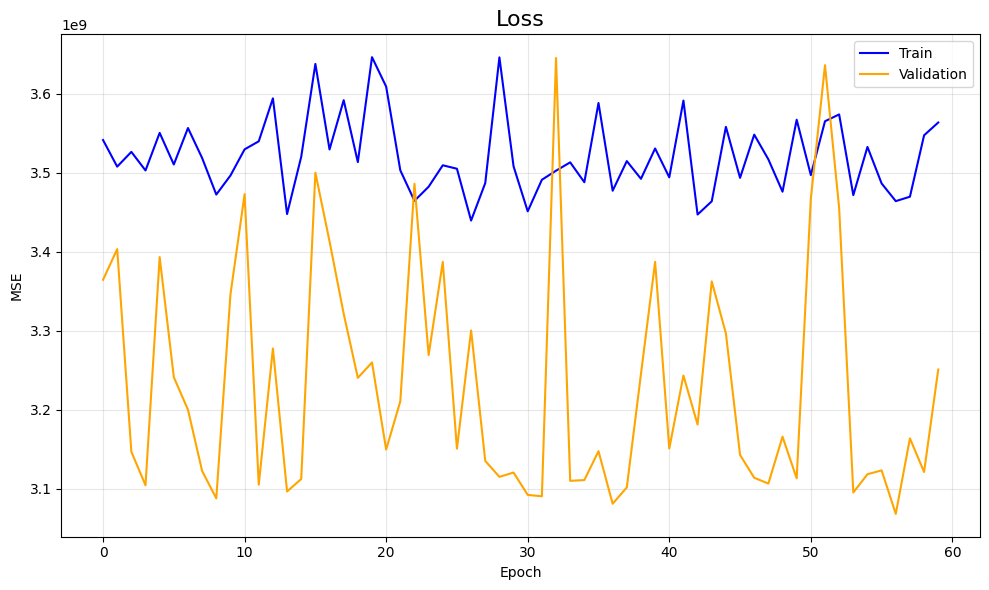

In [100]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(loss_list_train, label='Train', color='blue')
plt.plot(loss_list_val, label='Validation', color='orange')
plt.title('Loss', fontsize=16)
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# بخش 3-4

In [8]:
num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler())
])

preprocess = ColumnTransformer([
    ('num', num_pipe, numeric_features),
    ('cat', cat_pipe, categorical_features)
])

X_prep = preprocess.fit_transform(X)
X_prep = pd.DataFrame(X_prep)

X_outlier = X_prep[outlier_mask]

X_train, X_temp , y_train, y_temp = train_test_split(
    X_outlier, y_outlier, test_size=0.2, random_state=42
)

X_test, X_val, y_test, y_val = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)



X_train_t = torch.FloatTensor(X_train.to_numpy())
X_val_t   = torch.FloatTensor(X_val.to_numpy())
X_test_t  = torch.FloatTensor(X_test.to_numpy())
print(y_val.shape)
y_train_t = torch.FloatTensor(y_train.to_numpy()).view(-1, 1)
y_val_t   = torch.FloatTensor(y_val.to_numpy()).view(-1, 1)
y_test_t  = torch.FloatTensor(y_test.to_numpy()).view(-1, 1)
print(y_val_t.shape)

(1957,)
torch.Size([1957, 1])


In [9]:
batch_size     = 64
learning_rate  = 0.01
criterion      = nn.MSELoss()

train_ds = torch.utils.data.TensorDataset(X_train_t, y_train_t)
train_dl = torch.utils.data.DataLoader(train_ds, batch_size=batch_size, shuffle=True)

val_ds = torch.utils.data.TensorDataset(X_val_t, y_val_t)
val_dl = torch.utils.data.DataLoader(val_ds, batch_size=batch_size)

class HousePriceNetComplex(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(input_size, 9),
            nn.ReLU(),
            nn.BatchNorm1d(9),
            nn.Linear(9, 12),
            nn.ReLU(),
            nn.BatchNorm1d(12),
            nn.Linear(12, 9),
        
            nn.ReLU(),
            nn.Linear(9, 1)
        )

    def forward(self, x):
        return self.layers(x)

input_size = X_train.shape[1]
model = HousePriceNetComplex(input_size)
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

total_params = sum(p.numel() for p in model.parameters())
print(f"Total trainable parameters: {total_params}")

epochs = 60
best_val_loss = float('inf')
best_state = None
loss_list_train = []
loss_list_val = []

for epoch in range(1, epochs + 1):
    
    model.train()
    train_loss = 0.0
    for xb, yb in train_dl:
        pred = model(xb)
        loss = criterion(pred, yb)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        train_loss += loss.item() * xb.size(0)
    train_loss /= len(train_dl.dataset)
    loss_list_train.append(train_loss)

    
    model.eval()
    with torch.no_grad():
        val_preds = model(X_val_t).numpy().flatten()
        val_true = y_val_t.numpy().flatten()
        val_loss = my_mse(val_true, val_preds)
        loss_list_val.append(val_loss)

    if train_loss < best_val_loss - 1e-4:
        best_val_loss = train_loss
        best_state = model.state_dict()

    print(f"epoch  {epoch:03d} | train MSE: {train_loss:,.0f} | validation MSE: {val_loss:,.0f}")

model.load_state_dict(best_state)

model.eval()

Total trainable parameters: 415
epoch  001 | train MSE: 44,976,007,230 | validation MSE: 42,519,961,600
epoch  002 | train MSE: 35,117,641,090 | validation MSE: 23,129,595,904
epoch  003 | train MSE: 13,222,491,844 | validation MSE: 4,895,361,024
epoch  004 | train MSE: 4,205,815,383 | validation MSE: 2,982,225,920
epoch  005 | train MSE: 3,660,623,548 | validation MSE: 3,145,551,616
epoch  006 | train MSE: 3,355,536,822 | validation MSE: 2,770,760,960
epoch  007 | train MSE: 3,236,217,189 | validation MSE: 2,740,752,128
epoch  008 | train MSE: 3,310,575,863 | validation MSE: 2,650,790,912
epoch  009 | train MSE: 3,234,518,288 | validation MSE: 2,789,679,872
epoch  010 | train MSE: 3,054,858,634 | validation MSE: 2,842,255,872
epoch  011 | train MSE: 2,993,419,770 | validation MSE: 2,654,280,192
epoch  012 | train MSE: 2,979,345,815 | validation MSE: 2,600,924,160
epoch  013 | train MSE: 2,969,565,754 | validation MSE: 2,596,514,304
epoch  014 | train MSE: 2,948,321,586 | validation MS

HousePriceNetComplex(
  (layers): Sequential(
    (0): Linear(in_features=13, out_features=9, bias=True)
    (1): ReLU()
    (2): BatchNorm1d(9, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (3): Linear(in_features=9, out_features=12, bias=True)
    (4): ReLU()
    (5): BatchNorm1d(12, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): Linear(in_features=12, out_features=9, bias=True)
    (7): ReLU()
    (8): Linear(in_features=9, out_features=1, bias=True)
  )
)

In [10]:
with torch.no_grad():
    test_pred = model(X_test_t).numpy().flatten()
    test_true = y_test_t.numpy().flatten()

    final_train_pred = model(X_train_t).numpy().flatten()
    final_train_true = y_train_t.numpy().flatten()

    final_val_pred = model(X_val_t).numpy().flatten()
    final_val_true = y_val_t.numpy().flatten()

mse_train  = my_mse(final_train_true, final_train_pred)
rmse_train = my_rmse(final_train_true, final_train_pred)
mae_train  = my_mae(final_train_true, final_train_pred)
r2_train   = my_r2(final_train_true, final_train_pred)

mse_val  = my_mse(final_val_true, final_val_pred)
rmse_val = my_rmse(final_val_true, final_val_pred)
mae_val  = my_mae(final_val_true, final_val_pred)
r2_val   = my_r2(final_val_true, final_val_pred)


mse  = my_mse(test_true, test_pred)
rmse = my_rmse(test_true, test_pred)
mae  = my_mae(test_true, test_pred)
r2   = my_r2(test_true, test_pred)


print("\n" + "="*50)
print("total report of train")
print("="*50)
print(f"RMSE  : {rmse_train:,.0f} $")
print(f"MSE   : {mse_train:,.0f}")
print(f"MAE   : {mae_train:,.0f} $")
print(f"R²    : {r2_train:.4f}")

print("\n" + "="*50)
print("total report of Val")
print("="*50)
print(f"RMSE  : {rmse_val:,.0f} $")
print(f"MSE   : {mse_val:,.0f}")
print(f"MAE   : {mae_val:,.0f} $")
print(f"R²    : {r2_val:.4f}")

print("\n" + "="*50)
print("total report of test")
print("="*50)
print(f"RMSE  : {rmse:,.0f} $")
print(f"MSE   : {mse:,.0f}")
print(f"MAE   : {mae:,.0f} $")
print(f"R²    : {r2:.4f}")


total report of train
RMSE  : 49,429 $
MSE   : 2,443,274,496
MAE   : 35,355 $
R²    : 0.7307

total report of Val
RMSE  : 48,290 $
MSE   : 2,331,944,960
MAE   : 35,027 $
R²    : 0.7551

total report of test
RMSE  : 49,900 $
MSE   : 2,490,047,488
MAE   : 35,520 $
R²    : 0.7223


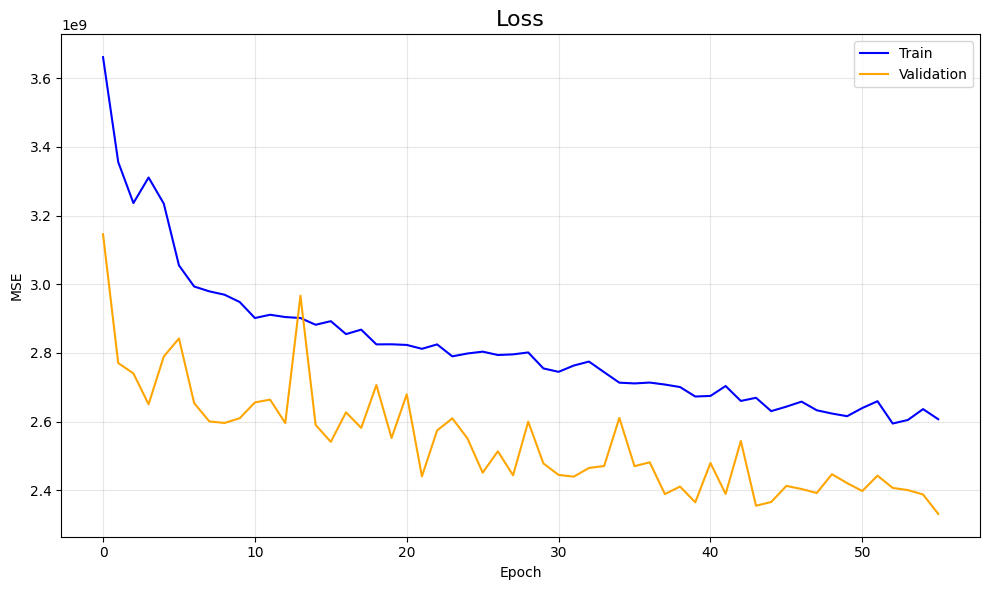

In [11]:
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 6))
plt.plot(loss_list_train[4:], label='Train', color='blue')
plt.plot(loss_list_val[4:], label='Validation', color='orange')
plt.title('Loss', fontsize=16)
plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

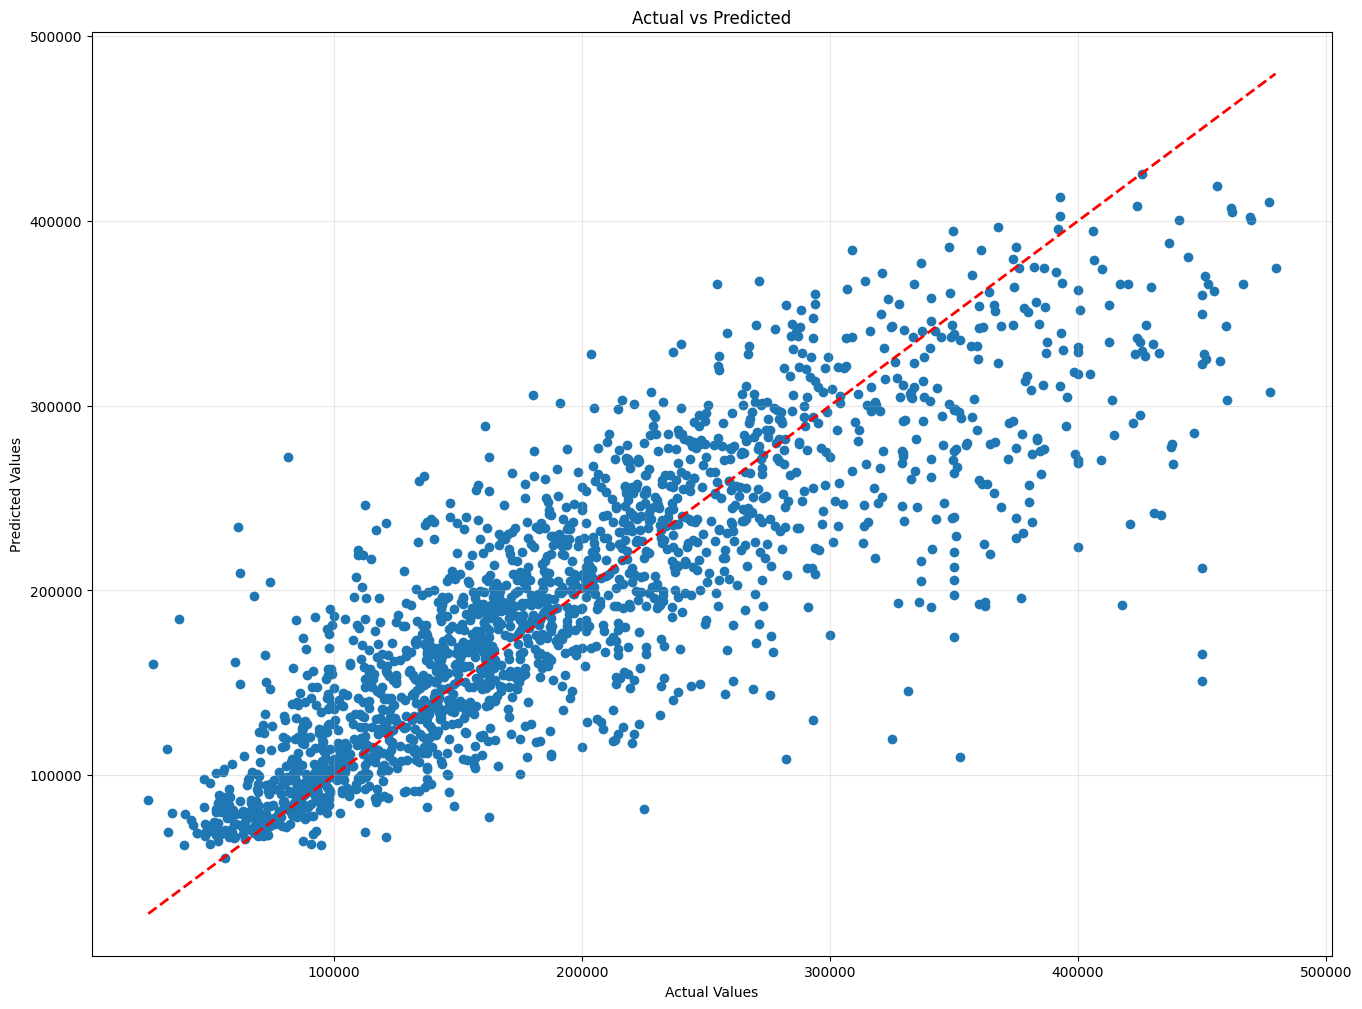

In [23]:
plt.figure(figsize=(16, 12))
plt.scatter(test_true,test_pred, alpha=1)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted')
plt.grid(True, alpha=0.3)
plt.show()